# NB16 — Thermal Generator + Hotspot Detection (R22)
Parameterized synthetic thermal frames (position, ΔT, size) extending the synthetic
injector; detector = background-relative threshold + connected components.
Gate: recall ≥ 0.90 at IoU ≥ 0.5 on held-out frames. Target: `aip_vision/thermal.py`.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter, label

DATA = Path("../../data")
IMG = 128
rng = np.random.default_rng(21)

In [2]:
def thermal_frame(seed, n_hot=None):
    r = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:IMG, 0:IMG]
    base = 30 + 4 * (xx / IMG) + gaussian_filter(r.normal(0, 0.6, (IMG, IMG)), 4)  # degC
    hots = []
    for _ in range(int(r.integers(1, 4)) if n_hot is None else n_hot):
        cx, cy = r.integers(15, IMG - 15, 2)
        rad, dT = int(r.integers(4, 10)), float(r.uniform(6, 25))
        heat = dT * np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * rad**2)))
        base += heat
        ys2, xs2 = np.where(heat > 1.0)          # GT = physically >1 degC added heat
        hots.append({"bbox": [int(xs2.min()), int(ys2.min()),
                              int(xs2.max()), int(ys2.max())],
                     "delta_t": round(dT, 1)})
    return base, hots

def detect_hotspots(frame, seed_dt=3.0, extent_dt=1.0, min_area=9):
    """Physical-unit hysteresis: extent at >1 degC above background, keep components
    whose peak exceeds seed_dt. Extent threshold matches the GT definition — in
    thermal work, degC is the shared language between detector and ground truth."""
    bg = gaussian_filter(frame, 20)
    resid = frame - bg
    lab, n = label(resid > extent_dt)
    out = []
    for i in range(1, n + 1):
        ys, xs = np.where(lab == i)
        peak = float(resid[ys, xs].max())
        if len(xs) < min_area or peak < seed_dt:
            continue
        out.append({"bbox": [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())],
                    "peak_dt": round(peak, 1)})
    return out

def iou(a, b):
    ix0, iy0 = max(a[0], b[0]), max(a[1], b[1])
    ix1, iy1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix1 - ix0) * max(0, iy1 - iy0)
    ar = lambda z: max((z[2] - z[0]) * (z[3] - z[1]), 1e-9)
    return inter / (ar(a) + ar(b) - inter)

## Evaluation on 30 held-out frames

hotspot recall@IoU0.5: 0.905  (57/63)


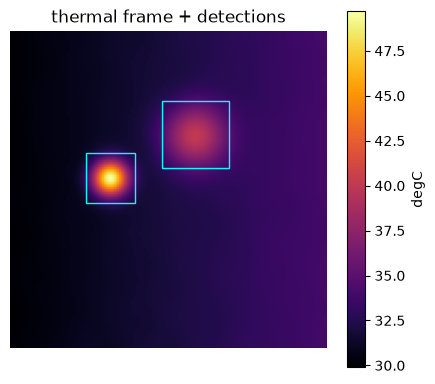

NB16 complete.


In [3]:
hits = tot = 0
frames = []
for i in range(30):
    fr, gts = thermal_frame(9000 + i)
    dets = detect_hotspots(fr)
    frames.append((fr, gts, dets))
    for g in gts:
        tot += 1
        hits += any(iou(g["bbox"], d["bbox"]) >= 0.5 for d in dets)
recall = hits / tot
print(f"hotspot recall@IoU0.5: {recall:.3f}  ({hits}/{tot})")
assert recall >= 0.90, "recall below gate"

fr, gts, dets = frames[0]
plt.figure(figsize=(4.5, 4))
plt.imshow(fr, cmap="inferno"); plt.colorbar(label="degC")
for d in dets:
    x0, y0, x1, y1 = d["bbox"]
    plt.gca().add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan"))
plt.title("thermal frame + detections"); plt.axis("off")
plt.tight_layout(); plt.savefig(DATA / "interim/nb16_thermal.png", dpi=110); plt.show()

sample = [{"frame": i, "hotspots": d} for i, (_, _, d) in enumerate(frames[:8])]
json.dump({"recall_iou50": round(recall, 4), "samples": sample},
          open(DATA / "processed/nb16_hotspots.json", "w"), indent=1)
print("NB16 complete.")